# Notebook 04 — reproducible baseline research

Restart the kernel, then Run All. This notebook loads the frozen N3 v24 output, trains the same baseline LightGBM, compares feature families on both development folds, and exports a review ZIP. The sealed holdout stays out of displays, fitting and scoring. Conditional labels remain separate; NaNs are not imputed.

The prior run stopped inside SHAP/Numba with a NumPy 1.x/2.x binary compatibility error. This version uses LightGBM's native TreeSHAP contributions and lightweight SVG displays, so it does not import SHAP, Numba or Matplotlib. It never installs or upgrades packages in a running kernel. This removes the failing dependency path; it does not repair your installed environment.

Required packages: numpy, pandas, pyarrow, scikit-learn, lightgbm, IPython. If a core import fails, repair those packages in a dedicated environment, select that environment's kernel, and restart. The environment report below records the interpreter and versions.

Change `SELECTED_FOLD` only in setup, then rerun from the top. All model settings remain the ones in your submitted notebook; no tuning is introduced.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
from IPython.display import display

# One frozen N3 run; change this path only here.
ARTIFACT_DIR = Path(
    "/Users/neilyejjey/stock_signal_engine_v2/data/interim/audits/"
    "nb03_history_v24/20261020T152222962533Z"
)
SEED = 42
pd.set_option("display.max_columns", 20)
print({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__})
import sys
from importlib.metadata import version
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor
SELECTED_FOLD = 0
MODEL_PARAMS = dict(objective="regression", n_estimators=200, learning_rate=0.03,
    num_leaves=15, min_child_samples=100, reg_lambda=1.0, random_state=SEED, n_jobs=4)
ENVIRONMENT = {"python":platform.python_version(), "executable":sys.executable,
    "packages":{name:version(name) for name in ["numpy","pandas","pyarrow","scikit-learn","lightgbm"]}}
print(json.dumps(ENVIRONMENT,indent=2))


{'python': '3.12.7', 'pandas': '2.2.2', 'numpy': '2.0.2'}
{
  "python": "3.12.7",
  "executable": "/opt/anaconda3/bin/python",
  "packages": {
    "numpy": "2.0.2",
    "pandas": "2.2.2",
    "pyarrow": "21.0.0",
    "scikit-learn": "1.5.2",
    "lightgbm": "4.6.0"
  }
}


## Load and validate the frozen dataset
Hashes are verified against the N3 contract before modeling. The full frame is retained for keyed validation, never displayed wholesale.

In [2]:
contract_path = ARTIFACT_DIR / "pretraining_contract.json"
print("Contract exists:", contract_path.is_file())

contract_path = ARTIFACT_DIR / "pretraining_contract.json"

if not contract_path.is_file():
    raise FileNotFoundError(f"Contract not found: {contract_path}")

contract = json.loads(contract_path.read_text())
if contract.get("status") != "TECHNICAL_HANDOFF_ACCEPTED_FOR_ARCHITECTURE_RESEARCH":
    raise ValueError("Notebook 3 technical handoff did not pass; inspect its report.")
checks = contract.get("technical_checks", {})
if not checks or not all(value is True for value in checks.values()):
    raise ValueError("Missing or failed Notebook 3 technical checks.")
KEYS = contract["keys"]
FEATURE_COLUMNS = contract["feature_columns"]
TARGET = contract["target"]
AVAILABLE = contract["availability_column"]
KIND = contract["outcome_kind_column"]
if KEYS != ["security_key", "as_of_date"]:
    raise ValueError("Unexpected key schema; review the changed contract.")
if not FEATURE_COLUMNS or len(set(FEATURE_COLUMNS)) != len(FEATURE_COLUMNS):
    raise ValueError("Invalid predictor whitelist.")
if set(FEATURE_COLUMNS) & set(KEYS + [TARGET, AVAILABLE, KIND]):
    raise ValueError("Predictor/metadata collision.")

frame_path = ARTIFACT_DIR / contract["frame_file"]
fold_path = ARTIFACT_DIR / contract["fold_membership_file"]
pretraining_frame_df = pd.read_parquet(frame_path)
fold_membership_df = pd.read_csv(fold_path, dtype={"security_key": "string"})

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

loaded_artifacts = {p.name: sha256_file(p) for p in [contract_path, frame_path, fold_path]}
print(json.dumps({"revision": contract["revision"], "source_fingerprint": contract.get("source_fingerprint"),
                  "loaded_sha256": loaded_artifacts}, indent=2))
for path in [frame_path, fold_path]:
    expected = contract.get("artifact_sha256", {}).get(path.name)
    if not expected or sha256_file(path) != expected:
        raise ValueError(f"Artifact checksum missing or mismatched: {path.name}")


Contract exists: True
{
  "revision": "nb03_v24_HISTORY_2016",
  "source_fingerprint": "b72f53c9d70c646513c0608141f75264d1fdb4168d8141d985e78c093760c818",
  "loaded_sha256": {
    "pretraining_contract.json": "900d638e7356e87668a8fb0a118dd05e0bf302b553028a8e74e1643d39937acc",
    "pretraining_frame.parquet": "5dbd09f54e092808bf012aa4d677b4cbc83b6db0c0483b001cdc8f5aa65864a2",
    "pretraining_fold_membership.csv": "7b1329b61f99ed008886c8bf990f262bc443b302aca41ae1f3232e598bc3694c"
  }
}


In [3]:
required = set(KEYS + FEATURE_COLUMNS + [TARGET, AVAILABLE, KIND, "target_end_date_12m",
    "feature_engineering_eligible", "exact_supervision_candidate", "conditional_supervision_candidate", "research_partition"])
missing = required - set(pretraining_frame_df.columns)
if missing:
    raise ValueError(f"Missing frame columns: {sorted(missing)}")
if not pretraining_frame_df.columns.is_unique:
    raise ValueError("Duplicate column names.")
if len(pretraining_frame_df) != contract["rows"] or len(FEATURE_COLUMNS) != contract["feature_count"]:
    raise ValueError("Frame dimensions disagree with contract.")
for df in [pretraining_frame_df, fold_membership_df]:
    df["security_key"] = df["security_key"].astype("string")
    df["as_of_date"] = pd.to_datetime(df["as_of_date"], errors="raise")
    if df[KEYS].isna().any().any():
        raise ValueError("Null security/date keys.")
for col in [AVAILABLE, "target_end_date_12m"]:
    pretraining_frame_df[col] = pd.to_datetime(pretraining_frame_df[col], errors="raise")
if pretraining_frame_df.duplicated(KEYS).any():
    raise ValueError("Duplicate security-months.")
non_numeric = [c for c in FEATURE_COLUMNS if not pd.api.types.is_numeric_dtype(pretraining_frame_df[c])]
if non_numeric:
    raise ValueError(f"Non-numeric predictors require review: {non_numeric}")
eligible = pretraining_frame_df["feature_engineering_eligible"].astype("boolean").fillna(False)
exact = eligible & pretraining_frame_df[KIND].eq("exact")
conditional = eligible & pretraining_frame_df[KIND].eq("conditional_interval")
for col, expected in [("exact_supervision_candidate", exact), ("conditional_supervision_candidate", conditional)]:
    if pretraining_frame_df[col].isna().any() or not pretraining_frame_df[col].astype(bool).eq(expected).all():
        raise ValueError(f"Inconsistent {col} flag.")
if not np.isfinite(pretraining_frame_df.loc[exact, TARGET].to_numpy(dtype=float)).all():
    raise ValueError("Exact candidate targets must be finite.")
if pretraining_frame_df.loc[conditional, TARGET].notna().any():
    raise ValueError("Conditional scenarios must not have imputed exact targets.")
holdout_dates = pretraining_frame_df.loc[pretraining_frame_df.research_partition.eq("sealed_holdout"), "as_of_date"]
if holdout_dates.empty:
    raise ValueError("Sealed holdout partition missing.")
HOLDOUT_START = holdout_dates.min()
print("Export schema checked. Holdout outcomes are not displayed or used below.")

Export schema checked. Holdout outcomes are not displayed or used below.


## Explicit fold selection
`get_fold` returns fresh exact-label X/y pairs and separate conditional rows. The selected fold updates all four X/y objects together.

In [4]:
membership_cols = KEYS + ["fold", "role", KIND]
if not set(membership_cols).issubset(fold_membership_df.columns) or fold_membership_df.empty:
    raise ValueError("Missing development fold membership.")
if fold_membership_df[membership_cols].isna().any().any():
    raise ValueError("Null fold metadata.")
if not fold_membership_df.role.isin(["train", "validation"]).all():
    raise ValueError("Unexpected fold role.")
if fold_membership_df.duplicated(["fold"] + KEYS).any():
    raise ValueError("Duplicate membership or train/validation overlap within a fold.")
fold_rows_df = fold_membership_df.rename(columns={KIND: "membership_kind"}).merge(
    pretraining_frame_df, on=KEYS, how="left", validate="many_to_one", indicator=True)
if not fold_rows_df["_merge"].eq("both").all():
    raise ValueError("Fold keys absent from frame.")
if not fold_rows_df.membership_kind.eq(fold_rows_df[KIND]).all():
    raise ValueError("Fold/frame observation kinds disagree.")
if not fold_rows_df.research_partition.eq("development_period").all():
    raise ValueError("Non-development rows in development folds.")
if not fold_rows_df.feature_engineering_eligible.fillna(False).all():
    raise ValueError("Feature-ineligible fold rows.")
if not fold_rows_df[KIND].isin(["exact", "conditional_interval"]).all():
    raise ValueError("Unsupported fold outcomes.")
for fold_id, rows in fold_rows_df.groupby("fold", sort=False):
    if set(rows.role) != {"train", "validation"}:
        raise ValueError(f"Fold {fold_id} lacks a train or validation partition.")
    validation_start = rows.loc[rows.role.eq("validation"), "as_of_date"].min()
    for role, subset in rows.groupby("role"):
        cutoff = validation_start if role == "train" else HOLDOUT_START
        if not ((subset[AVAILABLE] < cutoff) & (subset.target_end_date_12m < cutoff)).all():
            raise ValueError(f"Fold {fold_id}/{role}: outcome crosses its availability cutoff.")
        if role == "train" and not (subset.as_of_date < validation_start).all():
            raise ValueError("Training dates cross validation start.")
fold_rows_df = fold_rows_df.drop(columns=["_merge", "membership_kind"])
FOLD_IDS = fold_membership_df["fold"].drop_duplicates().tolist()

def get_fold(fold_id):
    """Fresh, key-indexed copies; metadata and conditional rows never enter X."""
    if fold_id not in FOLD_IDS:
        raise KeyError(f"Choose one of {FOLD_IDS}")
    result = {}
    for role in ["train", "validation"]:
        rows = fold_rows_df.loc[fold_rows_df.fold.eq(fold_id) & fold_rows_df.role.eq(role)].copy()
        rows = rows.set_index(KEYS).sort_index()
        exact_rows = rows.loc[rows[KIND].eq("exact")]
        if exact_rows.empty:
            raise ValueError(f"No exact outcomes for {fold_id}/{role}")
        result[role] = {
            "X": exact_rows.loc[:, FEATURE_COLUMNS].copy(),
            "y": exact_rows[TARGET].copy(),
            "metadata": exact_rows.drop(columns=FEATURE_COLUMNS).copy(),
            "conditional_rows": rows.loc[rows[KIND].eq("conditional_interval")].copy(),
        }
    return result

fold_summary = fold_rows_df.groupby(["fold", "role", KIND]).agg(
    rows=("security_key", "size"), first_date=("as_of_date", "min"), last_date=("as_of_date", "max"))
display(fold_summary)
selected_fold = SELECTED_FOLD
fold_data = get_fold(selected_fold)
X_train, y_train = fold_data["train"]["X"], fold_data["train"]["y"]
X_valid, y_valid = fold_data["validation"]["X"], fold_data["validation"]["y"]
train_metadata = fold_data["train"]["metadata"]
valid_metadata = fold_data["validation"]["metadata"]
print(f"Selected fold: {selected_fold}; X_train={X_train.shape}, X_valid={X_valid.shape}")

rows first_date  last_date
fold role       observation_kind                                 
0    train      exact                 29034 2016-01-29 2021-06-30
     validation conditional_interval      5 2022-07-29 2022-11-30
                exact                  2964 2022-07-29 2022-12-30
1    train      conditional_interval      1 2021-12-31 2021-12-31
                exact                 32006 2016-01-29 2021-12-31
     validation exact                  2942 2023-01-31 2023-06-30

Selected fold: 0; X_train=(29034, 64), X_valid=(2964, 64)


In [5]:
feature_audit_df = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_rows": X_train.isna().sum(),
    "missing_fraction": X_train.isna().mean(),
    "infinite_rows": np.isinf(X_train.to_numpy(dtype=float, na_value=np.nan)).sum(axis=0),
    "distinct_nonmissing": X_train.nunique(dropna=True),
}).sort_values("missing_fraction", ascending=False)
display(feature_audit_df)
display(X_train.head())
display(y_train.describe().to_frame("training_target"))
print("Target:", contract["target_definition"])
print("Source certification complete:", contract.get("source_certification_complete", False))
print("Upstream training authorized:", contract.get("training_authorized", False))
for limitation in contract.get("limitations", []):
    print("-", limitation)

,dtype,missing_rows,missing_fraction,infinite_rows,distinct_nonmissing
fund_fcf_growth_yoy,float64,3728,0.128401,0,8765
fund_cash_conversion_ttm,float64,2388,0.082248,0,9251
fund_net_income_growth_yoy,float64,2185,0.075257,0,9326
fund_interest_coverage_ttm,float64,1471,0.050665,0,9558
fund_operating_income_growth_yoy,float64,1366,0.047048,0,9624
...,...,...,...,...,...
price_total_return_63d,float64,0,0.000000,0,28901
price_total_return_21d,float64,0,0.000000,0,28824
fund_cash_to_assets,float64,0,0.000000,0,10054
fund_debt_to_assets,float64,0,0.000000,0,9853


fund_accruals_to_assets_ttm  fund_asset_turnover_ttm  \
security_key as_of_date                                                         
A            2016-01-29                    -0.011698                 0.441456   
             2016-02-29                    -0.011698                 0.441456   
             2016-03-31                    -0.024290                 0.545172   
             2016-04-29                    -0.024290                 0.545172   
             2016-05-31                    -0.024290                 0.545172   

                         fund_assets_growth_yoy  fund_capex_intensity_ttm  \
security_key as_of_date                                                     
A            2016-01-29                -0.30846                  0.024269   
             2016-02-29                -0.30846                  0.024269   
             2016-03-31                -0.02886                  0.025743   
             2016-04-29                -0.02886                  0.025743   
             2016-05-31                -0.02886                  0.025743   

                         fund_cash_conversion_ttm  fund_cash_growth_yoy  \
security_key as_of_date                                                   
A            2016-01-29                  1.266833             -0.096934   
             2016-02-29                  1.266833             -0.096934   
             2016-03-31                  1.392157             -0.088291   
             2016-04-29                  1.392157             -0.088291   
             2016-05-31                  1.392157             -0.088291   

                         fund_cash_to_assets  fund_cash_to_assets_change_yoy  \
security_key as_of_date                                                        
A            2016-01-29             0.267817                        0.062731   
             2016-02-29             0.267817                        0.062731   
             2016-03-31             0.264448                       -0.017238   
             2016-04-29             0.264448                       -0.017238   
             2016-05-31             0.264448                       -0.017238   

                         fund_current_ratio  fund_debt_growth_yoy  ...  \
security_key as_of_date                                            ...   
A            2016-01-29            3.776639             -0.004811  ...   
             2016-02-29            3.776639             -0.004811  ...   
             2016-03-31            3.589229              0.045235  ...   
             2016-04-29            3.589229              0.045235  ...   
             2016-05-31            3.589229              0.045235  ...   

                         price_idiosyncratic_vol_252d  \
security_key as_of_date                                 
A            2016-01-29                      0.137211   
             2016-02-29                      0.137803   
             2016-03-31                      0.140620   
             2016-04-29                      0.138696   
             2016-05-31                      0.145192   

                         price_drawdown_from_252d_high  price_beta_voo_252d  \
security_key as_of_date                                                       
A            2016-01-29                      -0.128341             1.135745   
             2016-02-29                      -0.135401             1.139810   
             2016-03-31                      -0.077660             1.169882   
             2016-04-29                      -0.029366             1.185958   
             2016-05-31                       0.000000             1.169650   

                         price_correlation_voo_252d  market_voo_return_21d  \
security_key as_of_date                                                      
A            2016-01-29                    0.802850              -0.065489   
             2016-02-29                    0.811643               0.023171   
             2016-03-31                    0.

,training_target
count,29034.000000
mean,-0.006229
std,0.304523
min,-0.980051
25%,-0.188631
50%,-0.028847
75%,0.143703
max,4.082681


Target: 12-month arithmetic stock-strategy return minus VOO return under the existing event convention
Source certification complete: False
Upstream training authorized: False
- Original/as-filed value provenance is incomplete across the remaining financial inputs; date checks do not establish value vintage.
- Historical security identity and split/dividend adjustment conventions are not independently certified across the whole price universe.
- Conditional return intervals are research scenarios, not observed returns, statistical confidence intervals or validated fair-value bounds; no midpoint imputation.
- Feature NaNs remain, including the reviewed liquidity exclusions. Any preprocessing must be fitted within training folds. Architecture cannot repair leakage or wrong security identity.
- Two development folds were available in v22. Overlapping 12-month labels and repeated events are dependent; keep the sealed holdout out of model selection.
- Reviewed event returns use documented e

## Baseline fit and prediction errors
All predictions carry the same security/date index as the outcomes. The mean benchmark is computed from this fold’s training labels only.

In [6]:
def score_predictions(actual, predicted):
    if not actual.index.equals(predicted.index):
        raise ValueError("Prediction and outcome indices/order differ")
    if not np.isfinite(actual.to_numpy(dtype=float)).all() or not np.isfinite(predicted.to_numpy(dtype=float)).all():
        raise ValueError("Non-finite outcome or prediction")
    return {"MAE":mean_absolute_error(actual,predicted),
            "RMSE":float(np.sqrt(mean_squared_error(actual,predicted)))}

def fit_predict(data, columns):
    train, valid = data["train"], data["validation"]
    if not train["X"].index.equals(train["y"].index) or not valid["X"].index.equals(valid["y"].index):
        raise ValueError("Misaligned X/y")
    fitted = LGBMRegressor(**MODEL_PARAMS)
    fitted.fit(train["X"].loc[:,columns],train["y"])
    predicted = pd.Series(fitted.predict(valid["X"].loc[:,columns]),index=valid["y"].index,name="predicted")
    return fitted,predicted

# Rebind together rather than changing fold_data alone.
fold_data = get_fold(SELECTED_FOLD)
X_train, y_train = fold_data["train"]["X"], fold_data["train"]["y"]
X_valid, y_valid = fold_data["validation"]["X"], fold_data["validation"]["y"]
print("training shape",X_train.shape)
print("validation shape",X_valid.shape)
model, predictions = fit_predict(fold_data,FEATURE_COLUMNS)
zero_predictions = pd.Series(0.,index=y_valid.index)
mean_predictions = pd.Series(y_train.mean(),index=y_valid.index)
scores = pd.DataFrame({"Predict zero":score_predictions(y_valid,zero_predictions),
    "Predict training mean":score_predictions(y_valid,mean_predictions),
    "LightGBM":score_predictions(y_valid,predictions)}).T
display(scores)
validation_results = pd.DataFrame({"actual":y_valid,"predicted":predictions})
validation_results["error"] = validation_results.predicted-validation_results.actual
display(validation_results.head(50))


training shape (29034, 64)
validation shape (2964, 64)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001574 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 15186
[LightGBM] [Info] Number of data points in the train set: 29034, number of used features: 64
[LightGBM] [Info] Start training from score -0.006229


,MAE,RMSE
Predict zero,0.226148,0.308616
Predict training mean,0.224025,0.306884
LightGBM,0.226206,0.330242


actual  predicted     error
security_key as_of_date                               
A            2022-07-29 -0.215651  -0.000627  0.215024
             2022-08-31 -0.208945   0.030125  0.239071
             2022-09-30 -0.290018   0.019645  0.309663
             2022-10-31 -0.348029  -0.000986  0.347043
             2022-11-30 -0.308201  -0.006373  0.301828
             2022-12-30 -0.327511   0.014824  0.342334
AAL          2022-07-29  0.091876   0.572250  0.480374
             2022-08-31 -0.025366   0.533425  0.558791
             2022-09-30 -0.152258   0.427397  0.579655
             2022-10-31 -0.314144   0.238059  0.552203
             2022-11-30 -0.277282   0.288209  0.565491
             2022-12-30 -0.183038   0.301293  0.484332
AAP          2022-07-29 -0.731770  -0.129709  0.602061
             2022-08-31 -0.736514  -0.142176  0.594338
             2022-09-30 -0.848807  -0.120109  0.728698
             2022-10-31 -0.817768  -0.125833  0.691935
             2022-11-30 -0.791550  -0.106697  0.684853
             2022-12-30 -0.839354  -0.110395  0.728959
AAPL         2022-07-29  0.086261   0.034855 -0.051406
             2022-08-31  0.042683   0.047572  0.004890
             2022-09-30  0.030045   0.047572  0.017527
             2022-10-31  0.019816   0.050259  0.030442
             2022-11-30  0.151698   0.070443 -0.081255
             2022-12-30  0.226863   0.090852 -0.136011
ABBV         2022-07-29 -0.045341  -0.055439 -0.010098
             2022-08-31 -0.022159  -0.065364 -0.043205
             2022-09-30 -0.060566  -0.069569 -0.009003
             2022-10-31 -0.097185  -0.073327  0.023858
             2022-11-30 -0.219629  -0.068229  0.151400
             2022-12-30 -0.265631  -0.064350  0.201281
ABT          2022-07-29 -0.087405  -0.012126  0.075279
             2022-08-31 -0.137651   0.020534  0.158186
             2022-09-30 -0.196032   0.016238  0.212269
             2022-10-31 -0.125670   0.018379  0.144050
             2022-11-30 -0.149822   0.004495  0.154317
             2022-12-30 -0.240609   0.010039  0.250648
ACGL         2022-10-31  0.406852  -0.128988 -0.535841
             2022-11-30  0.258194  -0.110045 -0.368239
             2022-12-30 -0.080312  -0.116360 -0.036047
ACN          2022-07-29 -0.080153   0.071869  0.152022
             2022-08-31 -0.018696   0.099475  0.118171
             2022-09-30 -0.003289   0.099475  0.102764
             2022-10-31 -0.037363   0.083134  0.120497
             2022-11-30 -0.014055   0.089726  0.103780
             2022-12-30  0.072728   0.100087  0.027359
ADBE         2022-07-29  0.201872   0.181801 -0.020071
             2022-08-31  0.338489   0.208704 -0.129785
             2022-09-30  0.636623   0.298793 -0.337830
             2022-10-31  0.570055   0.290919 -0.279136
             2022-11-30  0.632721   0.335249 -0.297473

In [7]:
diagnostics = validation_results.copy()

diagnostics["model_squared_error"] = diagnostics["error"] ** 2

#zero prediction error is 0 - actual; squaring removes the sign.
diagnostics["zero_squared_error"] = diagnostics["actual"] ** 2

diagnostics["extra_squared_error"] = (diagnostics["model_squared_error"] - diagnostics["zero_squared_error"])

display(diagnostics.sort_values("extra_squared_error", ascending = False,).head(50))

actual  predicted     error  model_squared_error  \
security_key as_of_date                                                       
SIVB         2022-10-31 -1.100247   1.013243  2.113489             4.466836   
             2022-11-30 -1.138596   0.990640  2.129235             4.533642   
             2022-12-30 -1.263083   0.881965  2.145048             4.601230   
SEDG         2022-10-31 -0.770289   0.859472  1.629761             2.656119   
ETSY         2022-10-31 -0.437062   1.013228  1.450290             2.103340   
DISH         2022-09-30 -0.792494   0.795093  1.587588             2.520435   
GNRC         2022-10-31 -0.375159   1.006395  1.381554             1.908692   
ETSY         2022-09-30 -0.571249   0.842177  1.413426             1.997774   
SIVB         2022-09-30 -1.215943   0.556140  1.772083             3.140278   
SBNY         2022-12-30 -1.249263   0.522154  1.771417             3.137917   
GNRC         2022-09-30 -0.604557   0.778748  1.383305             1.913533   
ETSY         2022-08-31 -0.462695   0.842177  1.304872             1.702691   
SEDG         2022-09-30 -0.656676   0.728648  1.385324             1.919123   
MTCH         2022-08-31 -0.330159   0.920092  1.250250             1.563126   
DISH         2022-07-29 -0.673326   0.692512  1.365838             1.865512   
             2022-10-31 -0.771824   0.639667  1.411492             1.992309   
GNRC         2022-08-31 -0.620274   0.675105  1.295379             1.678007   
SBNY         2022-11-30 -1.138321   0.464174  1.602495             2.567991   
GNRC         2022-11-30 -0.029224   1.097253  1.126477             1.268951   
LNC          2022-12-30 -0.318783   0.835006  1.153789             1.331228   
SBNY         2022-10-31 -1.100393   0.458605  1.558998             2.430475   
SEDG         2022-12-30 -0.932800   0.501218  1.434019             2.056409   
GNRC         2022-12-30  0.020699   1.106464  1.085765             1.178885   
DISH         2022-08-31 -0.813493   0.538216  1.351709             1.827117   
LNC          2022-11-30 -0.481612   0.668730  1.150342             1.323288   
DISH         2022-11-30 -0.910644   0.474899  1.385543             1.919729   
ENPH         2022-09-30 -0.783191   0.516638  1.299829             1.689556   
SIVB         2022-08-31 -1.159118   0.396103  1.555221             2.418713   
MTCH         2022-09-30 -0.395967   0.709675  1.105641             1.222443   
ETSY         2022-11-30 -0.564755   0.611547  1.176302             1.383686   
MTCH         2022-07-29 -0.495357   0.643542  1.138899             1.297092   
             2022-12-30 -0.383488   0.707216  1.090704             1.189636   
SIVB         2022-07-29 -1.129216   0.389071  1.518287             2.305195   
ETSY         2022-12-30 -0.586570   0.571944  1.158514             1.342155   
PYPL         2022-07-29 -0.253651   0.775305  1.028956             1.058750   
ENPH         2022-08-31 -0.717582   0.504179  1.221761             1.492700   
MTCH         2022-11-30 -0.498253   0.606553  1.104806             1.220596   
SEDG         2022-11-30 -0.873073   0.441202  1.314275             1.727318   
MTCH         2022-10-31 -0.299643   0.715676  1.015319             1.030873   
MRNA         2022-11-30 -0.696979   0.470416  1.167394             1.362810   
SEDG         2022-08-31 -0.570229   0.517473  1.087702             1.183095   
SBNY         2022-09-30 -1.216051   0.310709  1.526759             2.330994   
ENPH         2022-10-31 -0.841245   0.405851  1.247096             1.555248   
PYPL         2022-12-30 -0.401026   0.589134  0.990160             0.980417   
             2022-11-30 -0.403925   0.577736  0.981661             0.963658   
MRNA         2022-12-30 -0.709558   0.426762  1.136320             1.291224   
SBNY         2022-08-31 -1.158996   0.299554  1.458550             2.127369   
CTLT         2022-11-30 -0.363697   0.579050  0.942747             0.888772   
PENN         2022-08-31 -0.400749   0.530855  0.931604             0.867886  

## Native SHAP explanations — no SHAP package required

LightGBM `predict(..., pred_contrib=True)` returns one contribution per predictor and a final expected-value column. We verify that their sum reproduces the prediction. These are tree-path-based explanations of the fitted model, not causal effects.

Use SIVB/ETSY cases when present in the selected validation fold; otherwise use the largest excess squared-error cases. All reference medians and percentiles come from training only.

References: [LightGBM predict documentation](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.LGBMRegressor.html), [NumPy binary-compatibility troubleshooting](https://numpy.org/doc/2.0/user/troubleshooting-importerror.html).

In [8]:
case_keys = [("SIVB",pd.Timestamp("2022-10-31")),("ETSY",pd.Timestamp("2022-09-30"))]
case_keys = [key for key in case_keys if key in X_valid.index]
if not case_keys:
    case_keys = diagnostics.extra_squared_error.nlargest(2).index.tolist()
X_cases = X_valid.loc[case_keys,FEATURE_COLUMNS].copy()
contributions = np.asarray(model.predict(X_cases,pred_contrib=True),dtype=float)
if contributions.shape != (len(X_cases),len(FEATURE_COLUMNS)+1):
    raise ValueError("Unexpected contribution shape")
case_shap_values = contributions[:,:-1]
case_base_values = contributions[:,-1]
case_predictions = model.predict(X_cases)
np.testing.assert_allclose(contributions.sum(axis=1),case_predictions,rtol=1e-5,atol=1e-6)
np.testing.assert_allclose(case_predictions,validation_results.loc[X_cases.index,"predicted"],rtol=1e-5,atol=1e-6)
case_feature_details = {}
for position,key in enumerate(X_cases.index):
    details = pd.DataFrame({"case_value":X_cases.iloc[position],
        "shap_contribution":case_shap_values[position],"training_median":X_train.median(),
        "training_p05":X_train.quantile(.05),"training_p95":X_train.quantile(.95)})
    details["absolute_contribution"] = details.shap_contribution.abs()
    case_feature_details[key] = details.sort_values("absolute_contribution",ascending=False)
    print(key,"base:",case_base_values[position],"prediction:",case_predictions[position])
    display(case_feature_details[key].head(15))
feature_details = case_feature_details[X_cases.index[0]]
print("Native SHAP contributions reproduce the selected model predictions.")


('SIVB', Timestamp('2022-10-31 00:00:00')) base: -0.006237933329418131 prediction: 1.0132425352395895


,case_value,shap_contribution,training_median,training_p05,training_p95,absolute_contribution
price_realized_vol_126d,0.700957,0.319159,0.258900,0.146216,0.636860,0.319159
price_total_return_63d,-0.422874,0.140305,0.041842,-0.194123,0.278288,0.140305
price_downside_vol_252d,0.519265,0.132169,0.192132,0.106989,0.446225,0.132169
market_voo_drawdown_from_252d_high,-0.182323,0.092978,-0.012580,-0.126027,0.000000,0.092978
fund_cash_to_assets_change_yoy,-0.093948,0.079477,0.000289,-0.088895,0.089566,0.079477
price_realized_vol_252d,0.614822,0.069531,0.268333,0.156718,0.599401,0.069531
price_beta_voo_252d,1.567541,0.067174,1.001955,0.388359,1.633908,0.067174
price_drawdown_from_252d_high,-0.694105,0.053887,-0.082665,-0.386085,0.000000,0.053887
fund_shareholder_yield_dilution_component,-0.078003,-0.032984,0.008976,-0.087735,0.077023,0.032984
price_total_return_252d,-0.678060,0.027822,0.112408,-0.316268,0.679661,0.027822


('ETSY', Timestamp('2022-09-30 00:00:00')) base: -0.006237933329418131 prediction: 0.8421767638968487


,case_value,shap_contribution,training_median,training_p05,training_p95,absolute_contribution
price_realized_vol_126d,0.768644,0.270217,0.258900,0.146216,0.636860,0.270217
price_downside_vol_252d,0.550640,0.106486,0.192132,0.106989,0.446225,0.106486
price_beta_voo_252d,2.197359,0.095317,1.001955,0.388359,1.633908,0.095317
fund_cash_to_assets_change_yoy,-0.476019,0.069513,0.000289,-0.088895,0.089566,0.069513
price_drawdown_from_252d_high,-0.662760,0.064062,-0.082665,-0.386085,0.000000,0.064062
market_voo_drawdown_from_252d_high,-0.243721,0.063553,-0.012580,-0.126027,0.000000,0.063553
price_total_return_252d,-0.518513,0.057438,0.112408,-0.316268,0.679661,0.057438
price_realized_vol_252d,0.742921,0.053901,0.268333,0.156718,0.599401,0.053901
fund_sbc_to_revenue_ttm,0.085232,0.041731,0.006209,0.000000,0.056695,0.041731
price_total_return_63d,0.254605,-0.037299,0.041842,-0.194123,0.278288,0.037299


Native SHAP contributions reproduce the selected model predictions.


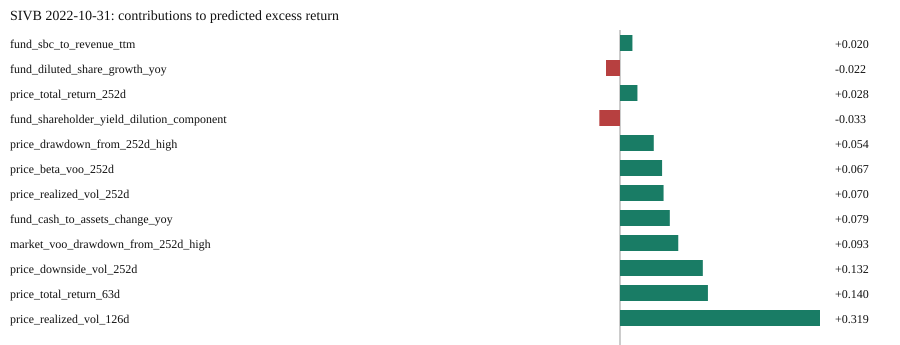

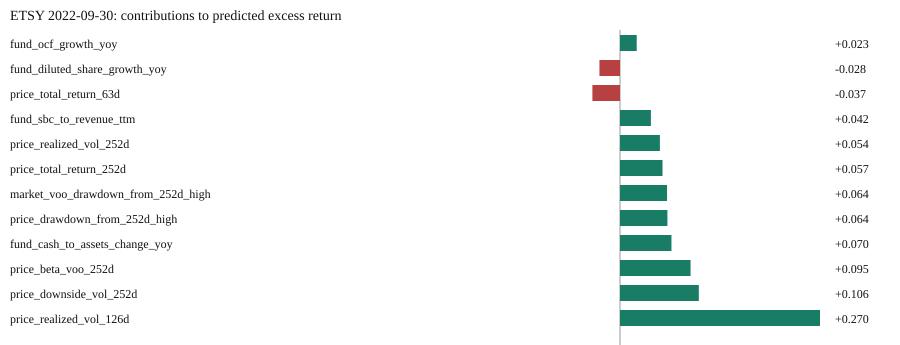

In [9]:
# Lightweight contribution display: no compiled plotting dependencies.
from html import escape
from IPython.display import SVG

def contribution_chart(details, title):
    top = details.head(12).iloc[::-1]
    largest = max(float(top.absolute_contribution.max()),1e-12)
    width,height,center = 900,45+25*len(top),620
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="10" y="20" fill="#111" font-size="14">{escape(title)}</text>',
        f'<line x1="{center}" x2="{center}" y1="30" y2="{height}" stroke="#999"/>']
    for i,(name,row) in enumerate(top.iterrows()):
        y=35+i*25;value=float(row.shap_contribution);length=abs(value)/largest*200
        x=center if value>=0 else center-length
        color="#197c65" if value>=0 else "#b74040"
        parts.extend([f'<text x="10" y="{y+13}" font-size="12" fill="#111">{escape(str(name))}</text>',
            f'<rect x="{x}" y="{y}" width="{length}" height="16" fill="{color}"/>',
            f'<text x="835" y="{y+13}" font-size="12" fill="#111">{value:+.3f}</text>'])
    return ''.join(parts)+"</svg>"
for key,details in case_feature_details.items():
    display(SVG(contribution_chart(details,f"{key[0]} {key[1]:%Y-%m-%d}: contributions to predicted excess return")))


## Both folds and feature-family comparisons
Each fit starts from the same parameter dictionary. The selected Combined model is reused, avoiding a duplicate fit. Other models are independently fitted on their own fold.

In [10]:

fundamental_features = [
    column for column in FEATURE_COLUMNS
    if column.startswith("fund_")
]

market_features = [
    column for column in FEATURE_COLUMNS
    if column.startswith(("price_", "market_"))
]

# Stop if any predictors haven't been classified.
assert set(fundamental_features + market_features) == set(FEATURE_COLUMNS)
assert fundamental_features and market_features

feature_groups = {
    "Market only": market_features,
    "Fundamentals only": fundamental_features,
    "Combined": list(FEATURE_COLUMNS),
}

for name, columns in feature_groups.items():
    print(name, ":", len(columns), "features")

Market only : 24 features
Fundamentals only : 40 features
Combined : 64 features


In [11]:
experiment_scores = []
experiment_predictions = {}
experiment_models = {}

for fold_id in FOLD_IDS:
    data = get_fold(fold_id)

    train_X = data["train"]["X"]
    train_y = data["train"]["y"]
    valid_X = data["validation"]["X"]
    valid_y = data["validation"]["y"]

    # Benchmarks use this fold's training data only.
    benchmarks = {
        "Predict zero": pd.Series(0.0, index=valid_y.index),
        "Predict training mean": pd.Series(
            train_y.mean(),
            index=valid_y.index,
        ),
    }

    for name, predicted in benchmarks.items():
        experiment_scores.append({
            "fold": fold_id,
            "model": name,
            **score_predictions(valid_y, predicted),
        })

    for name, columns in feature_groups.items():
        if fold_id == SELECTED_FOLD and name == "Combined":
            candidate, predicted = model, predictions.copy()
        else:
            candidate, predicted = fit_predict(data,columns)

        experiment_scores.append({
            "fold": fold_id,
            "model": name,
            **score_predictions(valid_y, predicted),
        })

        experiment_models[(fold_id, name)] = candidate

        experiment_predictions[(fold_id, name)] = pd.DataFrame({
            "actual": valid_y,
            "predicted": predicted,
        })

comparison = pd.DataFrame(experiment_scores)

display(
    comparison.set_index(["fold", "model"]).round(4)
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000436 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4986
[LightGBM] [Info] Number of data points in the train set: 29034, number of used features: 24
[LightGBM] [Info] Start training from score -0.006229
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001309 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 10200
[LightGBM] [Info] Number of data points in the train set: 29034, number of used features: 40
[LightGBM] [Info] Start training from score -0.006229
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000192 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not en

MAE    RMSE
fold model                                
0    Predict zero           0.2261  0.3086
     Predict training mean  0.2240  0.3069
     Market only            0.2284  0.3330
     Fundamentals only      0.2239  0.3097
     Combined               0.2262  0.3302
1    Predict zero           0.2535  0.3258
     Predict training mean  0.2534  0.3256
     Market only            0.2451  0.3298
     Fundamentals only      0.2531  0.3292
     Combined               0.2423  0.3281

## Drawdown diagnostics
The same buckets are used for training, validation, calendar-year and company summaries. These are descriptive diagnostics; repeated monthly observations have overlapping outcomes.

In [12]:
drawdown_feature = "price_drawdown_from_252d_high"

drawdown_edges = [
    -np.inf,
    -0.60,
    -0.40,
    -0.20,
    0.0,
    np.inf,
]

drawdown_labels = [
    "60%+ below high",
    "40–60% below high",
    "20–40% below high",
    "0–20% below high",
    "Above high: inspect",
]

training_summaries = []

for fold_id in FOLD_IDS:
    data = get_fold(fold_id)

    training_view = pd.DataFrame({
        "drawdown": data["train"]["X"][drawdown_feature],
        "actual": data["train"]["y"],
    })

    training_view["bucket"] = pd.cut(
        training_view["drawdown"],
        bins=drawdown_edges,
        labels=drawdown_labels,
        right=True,
    )

    # Keep missing drawdowns visible rather than silently dropping them.
    training_view["bucket"] = (
        training_view["bucket"]
        .cat.add_categories(["Missing"])
        .fillna("Missing")
    )

    training_view["security"] = (
        training_view.index.get_level_values("security_key")
    )

    training_view["outperformed"] = training_view["actual"] > 0

    summary = (
        training_view.groupby("bucket", observed=True)
        .agg(
            rows=("actual", "size"),
            securities=("security", "nunique"),
            mean_excess_return=("actual", "mean"),
            median_excess_return=("actual", "median"),
            outperformance_rate=("outperformed", "mean"),
        )
        .reset_index()
    )

    summary.insert(0, "fold", fold_id)
    training_summaries.append(summary)

training_drawdown_summary = pd.concat(
    training_summaries,
    ignore_index=True,
)

display(training_drawdown_summary.round(4))

,fold,bucket,rows,securities,mean_excess_return,median_excess_return,outperformance_rate
0,0,60%+ below high,217,56,0.5622,0.4740,0.7926
1,0,40–60% below high,1059,236,0.1814,0.1326,0.6185
2,0,20–40% below high,4875,502,0.0087,-0.0172,0.4790
3,0,0–20% below high,22871,552,-0.0235,-0.0357,0.4354
4,0,Missing,12,6,0.0792,0.0521,0.5833
5,1,60%+ below high,229,58,0.5218,0.4325,0.7642
6,1,40–60% below high,1083,240,0.1780,0.1276,0.6159
7,1,20–40% below high,5192,512,0.0105,-0.0184,0.4767
8,1,0–20% below high,25490,559,-0.0150,-0.0289,0.4479
9,1,Missing,12,6,0.0792,0.0521,0.5833


In [13]:
validation_summaries = []

for fold_id in FOLD_IDS:
    data = get_fold(fold_id)

    validation_view = experiment_predictions[
        (fold_id, "Combined")
    ].copy()

    validation_view["drawdown"] = (
        data["validation"]["X"][drawdown_feature]
    )

    validation_view["bucket"] = pd.cut(
        validation_view["drawdown"],
        bins=drawdown_edges,
        labels=drawdown_labels,
        right=True,
    )

    validation_view["bucket"] = (
        validation_view["bucket"]
        .cat.add_categories(["Missing"])
        .fillna("Missing")
    )

    validation_view["error"] = (
        validation_view["predicted"]
        - validation_view["actual"]
    )

    summary = (
        validation_view.groupby("bucket", observed=True)
        .agg(
            rows=("actual", "size"),
            mean_prediction=("predicted", "mean"),
            mean_actual=("actual", "mean"),
            mean_error=("error", "mean"),
        )
        .reset_index()
    )

    summary.insert(0, "fold", fold_id)
    validation_summaries.append(summary)

validation_drawdown_summary = pd.concat(
    validation_summaries,
    ignore_index=True,
)

display(validation_drawdown_summary.round(4))

,fold,bucket,rows,mean_prediction,mean_actual,mean_error
0,0,60%+ below high,72,0.5892,-0.0307,0.6198
1,0,40–60% below high,358,0.1378,-0.0345,0.1723
2,0,20–40% below high,1144,-0.0077,-0.0723,0.0646
3,0,0–20% below high,1388,-0.0644,-0.1195,0.0551
4,0,Missing,2,0.1941,0.1225,0.0715
5,1,60%+ below high,24,0.4023,-0.3964,0.7987
6,1,40–60% below high,116,0.1317,-0.1550,0.2867
7,1,20–40% below high,731,-0.0101,-0.1259,0.1159
8,1,0–20% below high,2071,-0.0460,-0.1012,0.0552


In [14]:
training_diagnostics = {}
date_ranges = []

for fold_id in FOLD_IDS:
    data = get_fold(fold_id)

    frame = pd.DataFrame({
        "drawdown": data["train"]["X"][drawdown_feature],
        "excess_return": data["train"]["y"],
    })

    frame["target_end_date"] = (
        data["train"]["metadata"]["target_end_date_12m"]
    )

    frame = frame.reset_index()

    # Year of the feature observation—not the outcome's ending year.
    frame["as_of_year"] = frame["as_of_date"].dt.year

    frame["bucket"] = pd.cut(
        frame["drawdown"],
        bins=drawdown_edges,
        labels=drawdown_labels,
        right=True,
    )

    frame["bucket"] = (
        frame["bucket"]
        .cat.add_categories(["Missing"])
        .fillna("Missing")
    )

    frame["outperformed"] = frame["excess_return"] > 0

    training_diagnostics[fold_id] = frame

    date_ranges.append({
        "fold": fold_id,
        "first_feature_date": frame["as_of_date"].min(),
        "last_feature_date": frame["as_of_date"].max(),
        "last_target_end_date": frame["target_end_date"].max(),
        "rows": len(frame),
        "securities": frame["security_key"].nunique(),
    })

display(pd.DataFrame(date_ranges))

,fold,first_feature_date,last_feature_date,last_target_end_date,rows,securities
0,0,2016-01-29,2021-06-30,2022-06-30,29034,564
1,1,2016-01-29,2021-12-31,2022-12-30,32006,572


In [15]:
yearly_tables = []

for fold_id, frame in training_diagnostics.items():
    summary = (
        frame.groupby(["as_of_year", "bucket"], observed=True)
        .agg(
            rows=("excess_return", "size"),
            securities=("security_key", "nunique"),
            mean_excess_return=("excess_return", "mean"),
            median_excess_return=("excess_return", "median"),
            outperformance_rate=("outperformed", "mean"),
        )
        .reset_index()
    )

    summary.insert(0, "fold", fold_id)
    yearly_tables.append(summary)

yearly_drawdown_summary = pd.concat(
    yearly_tables,
    ignore_index=True,
)

display(yearly_drawdown_summary.round(4))

,fold,as_of_year,bucket,rows,securities,mean_excess_return,median_excess_return,outperformance_rate
0,0,2016,60%+ below high,29,10,0.0972,0.0495,0.5517
1,0,2016,40–60% below high,149,54,0.0866,-0.0010,0.4966
2,0,2016,20–40% below high,810,223,0.0344,0.0220,0.5259
3,0,2016,0–20% below high,3828,404,-0.0170,-0.0290,0.4381
4,0,2017,60%+ below high,11,4,0.0134,0.0602,0.5455
5,0,2017,40–60% below high,69,21,0.0097,-0.0997,0.4348
6,0,2017,20–40% below high,451,105,-0.0059,-0.0473,0.4501
7,0,2017,0–20% below high,4462,424,-0.0207,-0.0420,0.4220
8,0,2018,60%+ below high,5,3,-0.2163,-0.6568,0.4000
9,0,2018,40–60% below high,133,61,-0.0408,-0.0273,0.4361


In [16]:
monthly_tables = []

for fold_id, frame in training_diagnostics.items():
    deep = frame.loc[frame["drawdown"] <= -0.40].copy()

    summary = (
        deep.groupby("as_of_date")
        .agg(
            rows=("excess_return", "size"),
            securities=("security_key", "nunique"),
            mean_excess_return=("excess_return", "mean"),
            median_excess_return=("excess_return", "median"),
        )
        .reset_index()
    )

    summary["share_of_deep_rows"] = (
        summary["rows"] / len(deep)
    )

    summary.insert(0, "fold", fold_id)
    monthly_tables.append(summary)

monthly_deep_summary = pd.concat(
    monthly_tables,
    ignore_index=True,
)

display(monthly_deep_summary.round(4))

,fold,as_of_date,rows,securities,mean_excess_return,median_excess_return,share_of_deep_rows
0,0,2016-01-29,39,39,0.1822,0.1834,0.0306
1,0,2016-02-29,33,33,0.1772,0.1261,0.0259
2,0,2016-03-31,18,18,0.1287,0.0475,0.0141
3,0,2016-04-29,19,19,0.0968,-0.0149,0.0149
4,0,2016-05-31,16,16,0.1167,-0.0564,0.0125
...,...,...,...,...,...,...,...
131,1,2021-08-31,3,3,-0.3363,-0.4285,0.0023
132,1,2021-09-30,4,4,-0.1719,-0.2009,0.0030
133,1,2021-10-29,4,4,-0.1118,-0.0905,0.0030
134,1,2021-11-30,14,14,0.0596,0.0654,0.0107


In [17]:
company_tables = []

for fold_id, frame in training_diagnostics.items():
    deep = frame.loc[frame["drawdown"] <= -0.40].copy()

    summary = (
        deep.groupby("security_key")
        .agg(
            rows=("excess_return", "size"),
            first_observation=("as_of_date", "min"),
            last_observation=("as_of_date", "max"),
            mean_excess_return=("excess_return", "mean"),
            median_excess_return=("excess_return", "median"),
            outperformance_rate=("outperformed", "mean"),
        )
        .reset_index()
    )

    summary["share_of_deep_rows"] = (
        summary["rows"] / len(deep)
    )

    summary.insert(0, "fold", fold_id)
    company_tables.append(summary)

company_deep_summary = pd.concat(
    company_tables,
    ignore_index=True,
)

for fold_id in FOLD_IDS:
    print(f"\nFold {fold_id}: most represented companies")

    display(
        company_deep_summary
        .loc[company_deep_summary["fold"] == fold_id]
        .sort_values(
            ["rows", "security_key"],
            ascending=[False, True],
        )
        .head(20)
        .round(4)
    )


Fold 0: most represented companies


,fold,security_key,rows,first_observation,last_observation,mean_excess_return,median_excess_return,outperformance_rate,share_of_deep_rows
143,0,MRO,24,2016-01-29,2020-12-31,0.4453,0.4740,0.6250,0.0188
64,0,DXC,21,2018-11-30,2020-11-30,-0.0395,-0.2695,0.4286,0.0165
88,0,GE,21,2017-11-30,2020-10-30,0.0531,-0.2149,0.4286,0.0165
205,0,UAA,21,2017-01-31,2020-09-30,0.3081,0.2695,0.6667,0.0165
17,0,APA,20,2016-02-29,2021-01-29,0.2342,0.0455,0.5500,0.0157
204,0,UA,20,2017-01-31,2020-09-30,0.2560,0.2036,0.6500,0.0157
223,0,WDC,20,2016-01-29,2020-10-30,0.3734,0.3146,0.8500,0.0157
178,0,RRC,17,2016-01-29,2018-04-30,-0.3334,-0.3062,0.0000,0.0133
184,0,SLB,17,2018-11-30,2020-12-31,0.0021,0.1344,0.5882,0.0133
47,0,COTY,16,2016-12-30,2020-08-31,0.2939,0.1728,0.6250,0.0125



Fold 1: most represented companies


,fold,security_key,rows,first_observation,last_observation,mean_excess_return,median_excess_return,outperformance_rate,share_of_deep_rows
384,1,MRO,24,2016-01-29,2020-12-31,0.4453,0.4740,0.6250,0.0183
303,1,DXC,21,2018-11-30,2020-11-30,-0.0395,-0.2695,0.4286,0.0160
327,1,GE,21,2017-11-30,2020-10-30,0.0531,-0.2149,0.4286,0.0160
447,1,UAA,21,2017-01-31,2020-09-30,0.3081,0.2695,0.6667,0.0160
255,1,APA,20,2016-02-29,2021-01-29,0.2342,0.0455,0.5500,0.0152
446,1,UA,20,2017-01-31,2020-09-30,0.2560,0.2036,0.6500,0.0152
465,1,WDC,20,2016-01-29,2020-10-30,0.3734,0.3146,0.8500,0.0152
420,1,RRC,17,2016-01-29,2018-04-30,-0.3334,-0.3062,0.0000,0.0130
426,1,SLB,17,2018-11-30,2020-12-31,0.0021,0.1344,0.5882,0.0130
285,1,COTY,16,2016-12-30,2020-08-31,0.2939,0.1728,0.6250,0.0122


## Export a review bundle

Only development predictions and diagnostics are exported. The original historical-coverage investigation belongs to N1–N3 and has been removed from this modeling notebook. Inputs are unchanged. Share the saved executed notebook and the review ZIP below.

In [18]:
import zipfile
RUN_DIR = ARTIFACT_DIR.parent.parent / "nb04_research" / pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True,exist_ok=False)
for name,table in {"selected_fold_scores":scores,"feature_family_scores":comparison,
    "validation_errors":validation_results,"worst_error_diagnostics":diagnostics,
    "training_drawdown":training_drawdown_summary,"validation_drawdown":validation_drawdown_summary,
    "yearly_drawdown":yearly_drawdown_summary,"monthly_deep_drawdown":monthly_deep_summary,
    "company_deep_drawdown":company_deep_summary}.items():
    table.to_csv(RUN_DIR/(name+".csv"),index=True)
all_predictions = pd.concat([table.assign(fold=key[0],model=key[1]) for key,table in experiment_predictions.items()])
all_predictions.to_csv(RUN_DIR/"development_predictions.csv")
for number,(key,details) in enumerate(case_feature_details.items()):
    details.to_csv(RUN_DIR/f"case_{number}_contributions.csv")
for key,expected in loaded_artifacts.items():
    if sha256_file(ARTIFACT_DIR/key)!=expected:raise ValueError("An input changed during execution")
manifest = {"environment":ENVIRONMENT,"model_params":MODEL_PARAMS,"selected_fold":SELECTED_FOLD,
    "artifact_dir":str(ARTIFACT_DIR),"input_sha256":loaded_artifacts,"feature_columns":FEATURE_COLUMNS,
    "source_fingerprint":contract.get("source_fingerprint"),"holdout_used":False,
    "explanation_method":"LightGBM native pred_contrib","cases":[[str(v) for v in k] for k in X_cases.index],
    "output_sha256":{p.name:sha256_file(p) for p in RUN_DIR.iterdir() if p.is_file()}}
(RUN_DIR/"run_manifest.json").write_text(json.dumps(manifest,indent=2))
bundle_path = RUN_DIR/"nb04_review_bundle.zip"
with zipfile.ZipFile(bundle_path,"w",zipfile.ZIP_DEFLATED) as bundle:
    for path in RUN_DIR.iterdir():
        if path!=bundle_path and path.is_file():bundle.write(path,path.name)
print("Review bundle:",bundle_path)


Review bundle: /Users/neilyejjey/stock_signal_engine_v2/data/interim/audits/nb04_research/20261104T194042878209Z/nb04_review_bundle.zip


In [29]:
# === PHASED STAGE 1 RESEARCH SUITE (PHASES 0–5, RED-TEAM AUDITED & PURGED) ===
# Phase 0: Outer-Fold Label-Maturity Proof & Bit-for-Bit Certified v26 Baseline Parity
# Phase 1: Cost-Sensitive Payoff Weighting Only (Unnormalized Clip -> Single Mean Normalization + N_eff Gate)
# Phase 2: Direct Utility Regression U(r) — L2 Squared-Error (E[U|X]) vs. Huber, Standalone & Ensemble Addition
# Phase 3: Forward-Only 4-Expert Purged OOF Mining + Out-of-Time Predictive Learnability Test (2018-19 -> 2020-21)
# Phase 4: 5th Compounder Specialist (Unconstrained Drawdown) — Standalone & Marginal Ensemble Test
# Phase 5: Limited Two-Way Interaction Check (Intrinsic Tail Recall@M & exploratory Stage 3 proxy)

MIN_ALLOWED_NEFF_RATIO = 0.80
W_MAX_CAP = 3.50


# ------------------------------------------------------------------------------
# 1. WEIGHTING, UTILITY, N_eff & DOWNSTREAM STAGE 3 VALIDITY GATE HELPERS
# ------------------------------------------------------------------------------
def compute_raw_cost_weights(
    y_cont: pd.Series,
    upside_hurdle: float = 0.10,
    downside_hurdle: float = -0.15,
    slope_up: float = 2.20,
    slope_dn: float = 2.20,
    power: float = 0.75,
    w_cap: float = W_MAX_CAP,
) -> np.ndarray:
    """Returns UNNORMALIZED raw payoff weights in [1.0, w_cap]."""
    r = y_cont.to_numpy(dtype=np.float64)
    up_term = np.maximum(0.0, r - upside_hurdle) ** power
    dn_term = np.maximum(0.0, downside_hurdle - r) ** power
    return np.clip(1.0 + slope_up * up_term + slope_dn * dn_term, 1.0, w_cap)


def combine_and_normalize_weights_once(
    raw_base_w: np.ndarray,
    raw_mult_w: np.ndarray = None,
    w_cap: float = W_MAX_CAP,
    STAGE1_TOP_FRACTION = 0.30,
    min_neff_ratio: float = MIN_ALLOWED_NEFF_RATIO,
) -> tuple[np.ndarray, float]:
    """Multiplies UNNORMALIZED base weights by UNNORMALIZED multipliers first,

    applies the [1.0, w_cap] cap once, normalizes to mean 1.0 once, and enforces
    Kish's Effective Sample Size threshold.
    """
    combined_raw = (
        raw_base_w.copy()
        if raw_mult_w is None
        else (raw_base_w * raw_mult_w)
    )
    capped_raw = np.clip(combined_raw, 1.0, w_cap)
    w_norm = capped_raw / np.mean(capped_raw)
    n_eff = float((np.sum(w_norm) ** 2) / max(np.sum(w_norm**2), 1e-12))
    neff_ratio = n_eff / max(len(w_norm), 1)
    assert neff_ratio >= min_neff_ratio, (
        f"Effective sample size ratio {neff_ratio:.3f} fell below minimum"
        f" {min_neff_ratio:.3f}!"
    )
    return w_norm, neff_ratio


def compute_direct_economic_utility(
    y_cont: pd.Series,
    upside_hurdle: float = 0.10,
    downside_hurdle: float = -0.15,
    a_up: float = 1.0,
    b_dn: float = 1.25,
    power: float = 0.75,
) -> pd.Series:
    r = y_cont.to_numpy(dtype=np.float64)
    u = np.zeros_like(r)
    pos = r > upside_hurdle
    neg = r < downside_hurdle
    u[pos] = a_up * ((r[pos] - upside_hurdle) ** power)
    u[neg] = -b_dn * ((downside_hurdle - r[neg]) ** power)
    return pd.Series(u, index=y_cont.index, name="economic_utility")


def newey_west_mean_se(values, max_lag: int = 11) -> float:
    """Bartlett/Newey-West HAC SE of a monthly sample mean (12m overlap: 11 lags).

    Requires >= 3 observed months; overlapping return horizons reduce the
    information available, so short-fold estimates remain highly uncertain.
    """
    x = np.asarray(values, dtype=np.float64)
    x = x[np.isfinite(x)]
    t = len(x)
    if t < 3:
        return float("nan")
    centered = x - x.mean()
    lag_count = min(max_lag, t - 1)
    long_run_var = float(np.dot(centered, centered) / t)
    for lag in range(1, lag_count + 1):
        gamma = float(np.dot(centered[lag:], centered[:-lag]) / t)
        long_run_var += 2.0 * (1.0 - lag / (lag_count + 1.0)) * gamma
    return float(np.sqrt(max(long_run_var, 0.0) / t))


def monthly_sieve_spreads(y_cont: pd.Series, score: pd.Series, top_fraction: float) -> pd.Series:
    """Monthly recalled-minus-pruned mean forward excess return, ordered by date."""
    selected = score.groupby(level="as_of_date").rank(pct=True) >= (1.0 - top_fraction)
    data = pd.DataFrame({"ex": y_cont, "sel": selected}, index=y_cont.index)
    result = {}
    for month, group in data.groupby(level="as_of_date", sort=True):
        recalled = group.loc[group["sel"], "ex"]
        pruned = group.loc[~group["sel"], "ex"]
        result[month] = (float(recalled.mean() - pruned.mean())
                         if len(recalled) and len(pruned) else float("nan"))
    return pd.Series(result, dtype="float64").sort_index().dropna()


STAGE1_TOP_FRACTION = 0.30

def evaluate_stage1_and_downstream_stage3(
    X_va: pd.DataFrame,
    y_va_cont: pd.Series,
    y_va_bin: pd.Series,
    stage1_score: pd.Series,
    fund_tree_rk: pd.Series,
    neff_ratio: float = 1.0,
    top_fraction: float = STAGE1_TOP_FRACTION,
    baseline_stage1_score: pd.Series = None,
) -> dict:
    """Stage 1 metrics, HAC uncertainty, and an EXPLORATORY Stage 3 heuristic.

    The Stage 3 score below is a proxy, not a call into the certified Stage 3.
    All return-based blowup metrics use EXCESS returns versus VOO.
    """
    ev = evaluate_stage1_sieve(
        y_va_cont, y_va_bin, stage1_score, top_fraction=top_fraction
    )
    rk_pct = stage1_score.groupby(level="as_of_date").rank(pct=True)
    sel_mask = rk_pct >= (1.0 - top_fraction)

    # Tail Recall@M at Stage 1 candidate budget (~148 stocks/month)
    w25_tot = int((y_va_cont >= 0.25).sum())
    w25_cap = int((y_va_cont.loc[sel_mask] >= 0.25).sum())
    w50_tot = int((y_va_cont >= 0.50).sum())
    w50_cap = int((y_va_cont.loc[sel_mask] >= 0.50).sum())

    # RELATIVE blowups: 12m stock excess return vs. VOO <= -40 percentage points.
    # This is not an absolute stock-loss count (raw stock returns are not passed here).
    recalled_blowup_cnt = int((y_va_cont.loc[sel_mask] <= -0.40).sum())

    # 12m rolling labels make consecutive monthly spreads serially dependent.
    # HAC uses Bartlett weights with up to 11 monthly lags (not naive std/sqrt(T)).
    df_eval = pd.DataFrame(
        {"ex": y_va_cont, "score": stage1_score, "sel": sel_mask},
        index=X_va.index,
    )
    monthly_spreads = monthly_sieve_spreads(y_va_cont, stage1_score, top_fraction)
    spread_se = newey_west_mean_se(monthly_spreads.to_numpy(), max_lag=11)

    # Paired, date-aligned experiment-minus-P0 inference isolates the actual uplift.
    delta_spread, paired_delta_hac_se = float("nan"), float("nan")
    if baseline_stage1_score is not None:
        baseline_monthly = monthly_sieve_spreads(y_va_cont, baseline_stage1_score, top_fraction)
        paired_delta = monthly_spreads.subtract(baseline_monthly).dropna()
        if len(paired_delta):
            delta_spread = float(paired_delta.mean())
            paired_delta_hac_se = newey_west_mean_se(paired_delta.to_numpy(), max_lag=11)

    # Stage 1 Unfiltered Top-20 Forward 12M Excess Return Diagnostic (not a monthly rebalanced backtest)
    top20_s1 = (
        df_eval.reset_index()
        .sort_values(["as_of_date", "score"], ascending=[True, False])
        .groupby("as_of_date")
        .head(20)
    )
    mean_fwd_12m_top20_diag = float(top20_s1["ex"].mean())

    # EXPLORATORY Stage 3 PROXY (not the certified downstream implementation).
    # Keep the supplied fundamental expert FIXED at the Phase 0 flat-weight baseline
    # across all experiments to avoid a second, hidden treatment variable.
    rec_X = X_va.loc[sel_mask]
    rec_y = y_va_cont.loc[sel_mask]
    rec_s1 = stage1_score.loc[sel_mask]
    rec_f_rk = fund_tree_rk.loc[sel_mask]

    q_fort = rec_X.get(
        "fund_fortress_quality_cs_score", pd.Series(0.5, index=rec_X.index)
    ).fillna(0.50)
    arch_fcf = rec_X.get(
        "fund_peer_archetype_fcf_rank", pd.Series(0.5, index=rec_X.index)
    ).fillna(0.50)
    ulcer_pct = rec_X.get(
        "price_ulcer_index_12m_cs_pct", pd.Series(0.5, index=rec_X.index)
    ).fillna(0.50)
    dd_raw = rec_X.get(
        "price_drawdown_from_252d_high", pd.Series(0.0, index=rec_X.index)
    ).fillna(0.0)
    dd_mag = dd_raw.clip(upper=0.0).abs()
    cash_burn = rec_X.get(
        "fund_drawdown_x_cash_burn", pd.Series(0.0, index=rec_X.index)
    ).fillna(0.0)
    stab_63d = rec_X.get(
        "price_drawdown_x_63d_stabilization", pd.Series(0.0, index=rec_X.index)
    ).fillna(0.0)
    op_chg = rec_X.get(
        "fund_operating_margin_change_yoy", pd.Series(0.0, index=rec_X.index)
    ).fillna(0.0)

    q_spring = (
        dd_mag * (q_fort - 0.60).clip(lower=0.0) + 0.5 * stab_63d.clip(lower=0.0)
    )
    q_knife = (
        -dd_mag * (1.0 - q_fort) * (0.50 + ulcer_pct)
        + 2.0 * cash_burn.clip(upper=0.0)
        + 0.5 * op_chg.clip(upper=0.0)
    )

    s1_in_rk = rec_s1.groupby(level="as_of_date").rank(pct=True).fillna(0.50)
    f_in_rk = rec_f_rk.groupby(level="as_of_date").rank(pct=True).fillna(0.50)
    qf_in_rk = (
        ((q_fort + arch_fcf) / 2.0)
        .groupby(level="as_of_date")
        .rank(pct=True)
        .fillna(0.50)
    )
    sp_in_rk = q_spring.groupby(level="as_of_date").rank(pct=True).fillna(0.50)
    kn_in_rk = q_knife.groupby(level="as_of_date").rank(pct=True).fillna(0.50)

    disq = (kn_in_rk <= 0.20) | ((dd_raw <= -0.35) & (q_fort <= 0.35))
    s3_score = (
        0.45 * s1_in_rk
        + 0.15 * f_in_rk
        + 0.25 * qf_in_rk
        + 0.15 * sp_in_rk
        + np.where(disq, -0.50, 0.0)
    )

    s3_df = pd.DataFrame({"ex": rec_y, "s3": s3_score}, index=rec_X.index).reset_index()
    top15_s3 = (
        s3_df.sort_values(["as_of_date", "s3"], ascending=[True, False])
        .groupby("as_of_date")
        .head(15)
    )

    return {
        "N_eff_Ratio": round(neff_ratio, 3),
        "ROC_AUC": round(ev["ROC_AUC"], 4),
        "PR_AUC": round(ev["PR_AUC"], 4),
        "Recall_>=10%@M": round(ev[f"Recall@Top{int(top_fraction*100)}%"], 4),
        "Tail_Recall_>=25%@M": round(w25_cap / max(w25_tot, 1), 4),
        "Tail_Recall_>=50%@M": round(w50_cap / max(w50_tot, 1), 4),
        "Outliers_>=25%_Cnt": f"{w25_cap}/{w25_tot}",
        "Mega_>=50%_Cnt": f"{w50_cap}/{w50_tot}",
        "Sieve_Spread": round(ev["Sieve_Spread_vs_Pruned"], 4),
        "Sieve_Spread_HAC_SE_11L": round(spread_se, 4),
        "Delta_Sieve_Spread_vs_P0": round(delta_spread, 4),
        "Delta_Sieve_Spread_HAC_SE_11L": round(paired_delta_hac_se, 4),
        "Sieve_Relative_Blowup_Rate": round(ev["Recalled_Tail_Blowup_Rate(<-40%)"], 4),
        "Sieve_Relative_Blowup_Cnt": recalled_blowup_cnt,
        "Mean_Fwd_12M_Excess_Top20_Diag": round(mean_fwd_12m_top20_diag, 4),
        "Exploratory_S3_Proxy_Top15_Fwd12M_Excess": round(float(top15_s3["ex"].mean()), 4),
        "Exploratory_S3_Proxy_Top15_Relative_Blowup_Rate": round(float((top15_s3["ex"] <= -0.40).mean()), 4),
    }


# ------------------------------------------------------------------------------
# 2. FORWARD-ONLY, LABEL-MATURED 4-EXPERT ENSEMBLE OOF GENERATOR
# ------------------------------------------------------------------------------
def compute_forward_only_purged_oof_4expert(
    X_tr: pd.DataFrame,
    y_tr_cont: pd.Series,
    y_tr_bin: pd.Series,
    meta_tr: pd.DataFrame,
    raw_base_weights: np.ndarray = None,
    top_fraction: float = STAGE1_TOP_FRACTION,
) -> pd.DataFrame:
    """Generates strictly forward-only, label-matured OOF predictions for the FULL

    4-Expert Baseline Ensemble (`0.45 Bagged + 0.30 Market + 0.15 Fund + 0.10
    Linear`), ensuring OOF blind spots reflect the actual deployed 4-expert
    ensemble.
    """
    dates = X_tr.index.get_level_values("as_of_date")
    target_end = pd.to_datetime(meta_tr["target_end_date_12m"])
    sup_avail = pd.to_datetime(meta_tr[AVAILABLE])

    block_starts = [
        pd.Timestamp("2018-01-01"),
        pd.Timestamp("2018-07-01"),
        pd.Timestamp("2019-01-01"),
        pd.Timestamp("2019-07-01"),
        pd.Timestamp("2020-01-01"),
        pd.Timestamp("2020-07-01"),
        pd.Timestamp("2021-01-01"),
        pd.Timestamp("2021-07-01"),
        pd.Timestamp("2022-01-01"),
    ]

    oof_ens_score = pd.Series(np.nan, index=X_tr.index, dtype="float64")
    X_ens = X_tr.loc[:, ENSEMBLE_ALL_COLS]
    mono_all = build_monotone_vector(ENSEMBLE_ALL_COLS)
    mono_mkt = build_monotone_vector(ENSEMBLE_MKT_COLS)
    mono_fund = build_monotone_vector(ENSEMBLE_FUND_COLS)

    for b_idx in range(len(block_starts) - 1):
        b_start, b_end = block_starts[b_idx], block_starts[b_idx + 1]
        val_mask = (dates >= b_start) & (dates < b_end)
        if not val_mask.any():
            continue

        # Strict Label-Maturity Purge: every training label must have completed strictly prior to `b_start`
        tr_mask = (
            (dates < b_start) & (target_end < b_start) & (sup_avail < b_start)
        )
        if int(tr_mask.sum()) < 1500:
            continue
        assert (target_end.loc[tr_mask] < b_start).all() and (
            sup_avail.loc[tr_mask] < b_start
        ).all()

        w_sub = None
        if raw_base_weights is not None:
            w_sub = raw_base_weights[tr_mask] / np.mean(raw_base_weights[tr_mask])

        X_tr_b, y_tr_b = X_ens.loc[tr_mask], y_tr_bin.loc[tr_mask]
        X_va_b = X_ens.loc[val_mask]

        cb = LGBMClassifier(**BAGGED_CLF_PARAMS, monotone_constraints=mono_all)
        cb.fit(X_tr_b, y_tr_b, sample_weight=w_sub)
        pb = pd.Series(cb.predict_proba(X_va_b)[:, 1], index=X_va_b.index)

        cm = LGBMClassifier(
            **dict(
                BAGGED_CLF_PARAMS,
                colsample_bytree=0.60,
                monotone_constraints=mono_mkt,
            )
        )
        cm.fit(
            X_tr_b.loc[:, ENSEMBLE_MKT_COLS], y_tr_b, sample_weight=w_sub
        )
        pm = pd.Series(
            cm.predict_proba(X_va_b.loc[:, ENSEMBLE_MKT_COLS])[:, 1],
            index=X_va_b.index,
        )

        cf = LGBMClassifier(
            **dict(
                BAGGED_CLF_PARAMS,
                colsample_bytree=0.50,
                monotone_constraints=mono_fund,
            )
        )
        cf.fit(
            X_tr_b.loc[:, ENSEMBLE_FUND_COLS], y_tr_b, sample_weight=w_sub
        )
        pf = pd.Series(
            cf.predict_proba(X_va_b.loc[:, ENSEMBLE_FUND_COLS])[:, 1],
            index=X_va_b.index,
        )

        _, pl, _ = fit_predict_linear_rank_expert_stable(X_tr_b, y_tr_b, X_va_b)

        ens_b = (
            0.45 * to_cs_rank(pb)
            + 0.30 * to_cs_rank(pm)
            + 0.15 * to_cs_rank(pf)
            + 0.10 * to_cs_rank(pl)
        )
        oof_ens_score.loc[val_mask] = ens_b

    oof_df = pd.DataFrame(
        {"actual_excess": y_tr_cont, "y_bin": y_tr_bin, "oof_score": oof_ens_score},
        index=X_tr.index,
    )
    valid_oof = oof_df["oof_score"].notna()
    oof_df["oof_cs_rank"] = np.nan
    oof_df.loc[valid_oof, "oof_cs_rank"] = (
        oof_df.loc[valid_oof]
        .groupby(level="as_of_date")["oof_score"]
        .rank(pct=True, ascending=True)
    )

    oof_df["is_oof_missed_winner"] = (
        valid_oof
        & (oof_df["actual_excess"] >= 0.20)
        & (oof_df["oof_cs_rank"] < (1.0 - top_fraction))
    )
    oof_df["is_oof_false_pos_blowup"] = (
        valid_oof
        & (oof_df["actual_excess"] <= -0.30)
        & (oof_df["oof_cs_rank"] >= (1.0 - top_fraction))
    )
    oof_df["raw_hard_mult"] = np.where(
        oof_df["is_oof_missed_winner"] | oof_df["is_oof_false_pos_blowup"],
        1.45,
        1.00,
    )
    return oof_df


# ------------------------------------------------------------------------------
# 3. EXECUTE PHASES 0 THROUGH 5 SEQUENTIALLY ACROSS BOTH DEVELOPMENT FOLDS
# ------------------------------------------------------------------------------
# Recover monotonicity constraints directly from the
# certified v26 constraint-building function.
base_mono_vec = build_monotone_vector(ENSEMBLE_ALL_COLS)

COMPOUNDER_5TH_MONO_MAP = {
    col: int(direction)
    for col, direction in zip(ENSEMBLE_ALL_COLS, base_mono_vec)
    if int(direction) != 0
    and not col.startswith("price_drawdown")
}
COMPOUNDER_5TH_MONO_MAP.update({
    "fund_fortress_quality_cs_score": 1,
    "fund_peer_archetype_fcf_rank": 1,
    "fund_peer_archetype_rev_share_gain": 1,
    "fund_productive_capex_compounder": 1,
    "price_momentum_12m_ex_1m": 1,
    "price_momentum_12m_ex_1m_cs_pct": 1,
    "price_martin_ratio_252d": 1,
    "price_martin_ratio_252d_cs_pct": 1,
})
# Prevent duplicate LightGBM feature names if fortress quality is already present.
FIFTH_EXPERT_COLS = list(dict.fromkeys(ENSEMBLE_ALL_COLS + ["fund_fortress_quality_cs_score"]))
assert len(FIFTH_EXPERT_COLS) == len(set(FIFTH_EXPERT_COLS))

phase0_audit_rows = []
phased_results_rows = []
oot_learnability_rows = []

for fold_id in FOLD_IDS:
    fdata = get_fold(fold_id)
    X_tr = fdata["train"]["X"]
    y_tr_cont = fdata["train"]["y"]
    y_tr_bin = fdata["train"]["y_bin"]
    meta_tr = fdata["train"]["metadata"]
    X_va = fdata["validation"]["X"]
    y_va_cont = fdata["validation"]["y"]
    y_va_bin = fdata["validation"]["y_bin"]
    meta_va = fdata["validation"]["metadata"]
    assert X_tr.index.equals(y_tr_cont.index) and X_tr.index.equals(y_tr_bin.index)
    assert X_tr.index.equals(meta_tr.index) and X_va.index.equals(meta_va.index)

    # ==========================================================================
    # PHASE 0: OUTER-FOLD LABEL-MATURITY PROOF & FROZEN v26 BASELINE PARITY
    # ==========================================================================
    tr_dates = X_tr.index.get_level_values("as_of_date")
    va_dates = X_va.index.get_level_values("as_of_date")
    val_start = va_dates.min()
    tr_target_end = pd.to_datetime(meta_tr["target_end_date_12m"])
    tr_sup_avail = pd.to_datetime(meta_tr[AVAILABLE])

    assert (tr_dates < val_start).all(), f"Fold {fold_id}: training as_of_date >= val_start!"
    assert (tr_target_end < val_start).all(), f"Fold {fold_id}: training target_end_date_12m >= val_start!"
    assert (tr_sup_avail < val_start).all(), f"Fold {fold_id}: training supervision_available_date >= val_start!"

    X_tr_ens = X_tr.loc[:, ENSEMBLE_ALL_COLS]
    X_va_ens = X_va.loc[:, ENSEMBLE_ALL_COLS]
    mono_all = build_monotone_vector(ENSEMBLE_ALL_COLS)
    mono_mkt = build_monotone_vector(ENSEMBLE_MKT_COLS)
    mono_fund = build_monotone_vector(ENSEMBLE_FUND_COLS)
    mono_5th = build_monotone_vector(FIFTH_EXPERT_COLS, COMPOUNDER_5TH_MONO_MAP)

    _, p_lin, _ = fit_predict_linear_rank_expert_stable(X_tr_ens, y_tr_bin, X_va_ens)
    r_lin = to_cs_rank(p_lin)

    def fit_4expert_ensemble(w_norm_vec: np.ndarray = None):
        cb = LGBMClassifier(**BAGGED_CLF_PARAMS, monotone_constraints=mono_all)
        cb.fit(X_tr_ens, y_tr_bin, sample_weight=w_norm_vec)
        rb = to_cs_rank(pd.Series(cb.predict_proba(X_va_ens)[:, 1], index=X_va.index))

        cm = LGBMClassifier(
            **dict(BAGGED_CLF_PARAMS, colsample_bytree=0.60, monotone_constraints=mono_mkt)
        )
        cm.fit(X_tr_ens.loc[:, ENSEMBLE_MKT_COLS], y_tr_bin, sample_weight=w_norm_vec)
        rm = to_cs_rank(
            pd.Series(cm.predict_proba(X_va_ens.loc[:, ENSEMBLE_MKT_COLS])[:, 1], index=X_va.index)
        )

        cf = LGBMClassifier(
            **dict(BAGGED_CLF_PARAMS, colsample_bytree=0.50, monotone_constraints=mono_fund)
        )
        cf.fit(X_tr_ens.loc[:, ENSEMBLE_FUND_COLS], y_tr_bin, sample_weight=w_norm_vec)
        rf = to_cs_rank(
            pd.Series(cf.predict_proba(X_va_ens.loc[:, ENSEMBLE_FUND_COLS])[:, 1], index=X_va.index)
        )

        ens = 0.45 * rb + 0.30 * rm + 0.15 * rf + 0.10 * r_lin
        return ens, rb, rm, rf

    p_P0_control, rb_flat, rm_flat, rf_flat = fit_4expert_ensemble(None)
    frozen_v26_prob = stage1_probabilities[(fold_id, CANONICAL_STAGE1_MODEL)]
    assert p_P0_control.index.equals(frozen_v26_prob.index), "Frozen baseline index/order mismatch"
    parity_diff = float(np.max(np.abs(p_P0_control.to_numpy() - frozen_v26_prob.to_numpy())))
    assert parity_diff < 1e-12, f"Phase 0 Baseline Parity Failed on Fold {fold_id}: {parity_diff}"

    phase0_audit_rows.append({
        "fold": fold_id,
        "train_rows": len(X_tr),
        "last_train_as_of_date": tr_dates.max().strftime("%Y-%m-%d"),
        "last_train_label_maturity_date": tr_target_end.max().strftime("%Y-%m-%d"),
        "first_validation_as_of_date": val_start.strftime("%Y-%m-%d"),
        "outer_purge_gap_days": int((val_start - tr_target_end.max()).days),
        "frozen_v26_max_abs_diff": f"{parity_diff:.2e}",
        "outer_purge_and_parity_verified": True,
    })

    phased_results_rows.append({
        "fold": fold_id,
        "phase_experiment": "Phase 0: Certified v26 Baseline Control (4-Expert, Flat Weights)",
        **evaluate_stage1_and_downstream_stage3(
            X_va, y_va_cont, y_va_bin, p_P0_control, rf_flat, neff_ratio=1.000
        ),
    })

    # ==========================================================================
    # PHASE 1: COST-SENSITIVE PAYOFF WEIGHTING ONLY (NO OOF MINING, NO 5TH EXPERT)
    # ==========================================================================
    raw_w_cost = compute_raw_cost_weights(y_tr_cont, w_cap=W_MAX_CAP)
    w_P1_norm, neff_P1 = combine_and_normalize_weights_once(raw_w_cost, None, w_cap=W_MAX_CAP)
    p_P1_cost, rb_cost, rm_cost, rf_cost = fit_4expert_ensemble(w_P1_norm)

    phased_results_rows.append({
        "fold": fold_id,
        "phase_experiment": "Phase 1: Cost-Sensitive Payoff Weighting Only (4-Expert)",
        **evaluate_stage1_and_downstream_stage3(
            X_va, y_va_cont, y_va_bin, p_P1_cost, rf_flat, neff_ratio=neff_P1,
            baseline_stage1_score=p_P0_control
        ),
    })

    # ==========================================================================
    # PHASE 2: DIRECT CONCAVE UTILITY REGRESSION U(r) — L2 (E[U|X]) VS. HUBER
    # ==========================================================================
    y_tr_util = compute_direct_economic_utility(y_tr_cont)

    # P2a: L2 Squared-Error Regression on U(r) (estimates true conditional expectation E[U(R)|X])
    L2_UTIL_PARAMS = dict(
        objective="regression",
        n_estimators=250,
        learning_rate=0.025,
        num_leaves=15,
        min_child_samples=120,
        colsample_bytree=0.45,
        subsample=0.75,
        subsample_freq=1,
        reg_lambda=5.0,
        random_state=SEED,
        n_jobs=4,
        verbose=-1,
    )
    reg_util_l2 = LGBMRegressor(**L2_UTIL_PARAMS, monotone_constraints=mono_all)
    reg_util_l2.fit(X_tr_ens, y_tr_util)
    r_util_l2 = to_cs_rank(pd.Series(reg_util_l2.predict(X_va_ens), index=X_va.index))

    # P2b: Huber Regression on U(r) (robust conditional location)
    reg_util_huber = LGBMRegressor(**dict(HUBER_REG_PARAMS, monotone_constraints=mono_all))
    reg_util_huber.fit(X_tr_ens, y_tr_util)
    r_util_huber = to_cs_rank(pd.Series(reg_util_huber.predict(X_va_ens), index=X_va.index))

    for p2_name, p2_score in [
        ("Phase 2a: Direct Utility U(r) Standalone — L2 Squared-Error (E[U|X])", r_util_l2),
        ("Phase 2b: Direct Utility U(r) Standalone — Huber Loss", r_util_huber),
        ("Phase 2c: 4-Expert + L2 Utility U(r) Blend (85/15)", 0.85 * p_P0_control + 0.15 * r_util_l2),
        ("Phase 2d: 4-Expert + Huber Utility U(r) Blend (85/15)", 0.85 * p_P0_control + 0.15 * r_util_huber),
    ]:
        phased_results_rows.append({
            "fold": fold_id,
            "phase_experiment": p2_name,
            **evaluate_stage1_and_downstream_stage3(
                X_va, y_va_cont, y_va_bin, p2_score, rf_flat, neff_ratio=1.000,
                baseline_stage1_score=p_P0_control
            ),
        })

    # ==========================================================================
    # PHASE 3: FORWARD-ONLY 4-EXPERT PURGED OOF MINING & OUT-OF-TIME LEARNABILITY TEST
    # ==========================================================================
    oof_4exp_df = compute_forward_only_purged_oof_4expert(
        X_tr, y_tr_cont, y_tr_bin, meta_tr, raw_base_weights=None
    )

    # Matched OOT test: identical specialist, same data/cutoff, flat vs. OOF-hard weights.
    # Early OOF error labels must mature before 2020-07-01; test later rows only.
    early_oof_mask = (
        oof_4exp_df["oof_cs_rank"].notna()
        & (tr_dates >= pd.Timestamp("2018-01-01"))
        & (tr_dates <= pd.Timestamp("2019-06-30"))
        & (tr_target_end < pd.Timestamp("2020-07-01"))
        & (tr_sup_avail < pd.Timestamp("2020-07-01"))
    )
    late_oof_mask = (
        oof_4exp_df["oof_cs_rank"].notna()
        & (tr_dates >= pd.Timestamp("2020-07-01"))
    )
    if early_oof_mask.any() and late_oof_mask.any():
        # Fixed historical cutoff. Change only the specialist's sample weights.
        pre_2020_mask = (
            (tr_dates < pd.Timestamp("2020-07-01"))
            & (tr_target_end < pd.Timestamp("2020-07-01"))
            & (tr_sup_avail < pd.Timestamp("2020-07-01"))
        )
        w_oot_raw = oof_4exp_df.loc[pre_2020_mask, "raw_hard_mult"].to_numpy(dtype=np.float64)
        w_oot_norm = w_oot_raw / np.mean(w_oot_raw)

        X_early = X_tr_ens.loc[pre_2020_mask]
        y_early = y_tr_bin.loc[pre_2020_mask]
        X_late = X_tr_ens.loc[late_oof_mask]
        c_oot_flat = LGBMClassifier(**BAGGED_CLF_PARAMS, monotone_constraints=mono_all)
        c_oot_hard = LGBMClassifier(**BAGGED_CLF_PARAMS, monotone_constraints=mono_all)
        c_oot_flat.fit(X_early, y_early)
        c_oot_hard.fit(X_early, y_early, sample_weight=w_oot_norm)
        p_flat_late = to_cs_rank(pd.Series(c_oot_flat.predict_proba(X_late)[:, 1], index=X_late.index))
        p_hard_late = to_cs_rank(pd.Series(c_oot_hard.predict_proba(X_late)[:, 1], index=X_late.index))

        # Common baseline and blend coefficient for both treatments.
        base_late_rk = oof_4exp_df.loc[late_oof_mask, "oof_cs_rank"]
        flat_blend = (0.70 * base_late_rk + 0.30 * p_flat_late).groupby(level="as_of_date").rank(pct=True)
        hard_blend = (0.70 * base_late_rk + 0.30 * p_hard_late).groupby(level="as_of_date").rank(pct=True)

        y_late_cont = y_tr_cont.loc[late_oof_mask]
        w25_late_tot = int((y_late_cont >= 0.25).sum())
        base_w25_rec = float((y_late_cont.loc[base_late_rk >= 0.70] >= 0.25).sum() / max(w25_late_tot, 1))
        flat_w25_rec = float((y_late_cont.loc[flat_blend >= 0.70] >= 0.25).sum() / max(w25_late_tot, 1))
        hard_w25_rec = float((y_late_cont.loc[hard_blend >= 0.70] >= 0.25).sum() / max(w25_late_tot, 1))

        oot_learnability_rows.append({
            "fold": fold_id,
            "early_matured_train_rows": int(pre_2020_mask.sum()),
            "later_oot_test_rows": int(late_oof_mask.sum()),
            "late_oof_4expert_Recall_>=25%": round(base_w25_rec, 4),
            "late_flat_specialist_blend_Recall_>=25%": round(flat_w25_rec, 4),
            "late_hard_specialist_blend_Recall_>=25%": round(hard_w25_rec, 4),
            "delta_OOT_hard_minus_flat_Recall_>=25%": round(hard_w25_rec - flat_w25_rec, 4),
        })

    w_P3_norm, neff_P3 = combine_and_normalize_weights_once(
        np.ones(len(X_tr), dtype=np.float64),
        oof_4exp_df["raw_hard_mult"].to_numpy(dtype=np.float64),
        w_cap=W_MAX_CAP,
    )
    p_P3_oof, rb_oof, rm_oof, rf_oof = fit_4expert_ensemble(w_P3_norm)

    phased_results_rows.append({
        "fold": fold_id,
        "phase_experiment": "Phase 3: Forward-Only 4-Expert Purged OOF Mining Only",
        **evaluate_stage1_and_downstream_stage3(
            X_va, y_va_cont, y_va_bin, p_P3_oof, rf_flat, neff_ratio=neff_P3,
            baseline_stage1_score=p_P0_control
        ),
    })

    # ==========================================================================
    # PHASE 4: 5TH COMPOUNDER SPECIALIST (UNCONSTRAINED DRAWDOWN) — STANDALONE & MARGINAL
    # ==========================================================================
    c5_flat = LGBMClassifier(
        **dict(BAGGED_CLF_PARAMS, colsample_bytree=0.50, monotone_constraints=mono_5th)
    )
    c5_flat.fit(X_tr.loc[:, FIFTH_EXPERT_COLS], y_tr_bin)
    r_c5_flat = to_cs_rank(
        pd.Series(c5_flat.predict_proba(X_va.loc[:, FIFTH_EXPERT_COLS])[:, 1], index=X_va.index)
    )
    p_P4_ens = 0.38 * rb_flat + 0.25 * rm_flat + 0.12 * rf_flat + 0.15 * r_c5_flat + 0.10 * r_lin

    for p4_name, p4_score in [
        ("Phase 4a: 5th Compounder Specialist Standalone (Flat Weights)", r_c5_flat),
        ("Phase 4b: 4-Expert + 5th Compounder Specialist (85/15 Blend, Flat Weights)", p_P4_ens),
    ]:
        phased_results_rows.append({
            "fold": fold_id,
            "phase_experiment": p4_name,
            **evaluate_stage1_and_downstream_stage3(
                X_va, y_va_cont, y_va_bin, p4_score, rf_flat, neff_ratio=1.000,
                baseline_stage1_score=p_P0_control
            ),
        })

    # ==========================================================================
    # PHASE 5: CURATED TWO-WAY INTERACTIONS (CORRECTED SINGLE-CLIP NORMALIZATION)
    # ==========================================================================
    # Interaction 5a: Cost-Sensitive Weighting + 4-Expert Purged OOF Mining (Unnormalized multiply -> single clip -> single norm)
    oof_4exp_cost_df = compute_forward_only_purged_oof_4expert(
        X_tr, y_tr_cont, y_tr_bin, meta_tr, raw_base_weights=raw_w_cost
    )
    w_P5a_norm, neff_P5a = combine_and_normalize_weights_once(
        raw_w_cost,
        oof_4exp_cost_df["raw_hard_mult"].to_numpy(dtype=np.float64),
        w_cap=W_MAX_CAP,
    )
    p_P5a_comb, rb_c_oof, rm_c_oof, rf_c_oof = fit_4expert_ensemble(w_P5a_norm)

    # Interaction 5b: Cost-Sensitive Weighting + L2 Direct Utility U(r) Blend
    p_P5b_cost_util = 0.85 * p_P1_cost + 0.15 * r_util_l2

    # Interaction 5c: Cost-Sensitive Weighting + 5th Compounder Specialist
    c5_cost = LGBMClassifier(
        **dict(BAGGED_CLF_PARAMS, colsample_bytree=0.50, monotone_constraints=mono_5th)
    )
    c5_cost.fit(X_tr.loc[:, FIFTH_EXPERT_COLS], y_tr_bin, sample_weight=w_P1_norm)
    r_c5_cost = to_cs_rank(
        pd.Series(c5_cost.predict_proba(X_va.loc[:, FIFTH_EXPERT_COLS])[:, 1], index=X_va.index)
    )
    p_P5c_cost_5th = 0.38 * rb_cost + 0.25 * rm_cost + 0.12 * rf_cost + 0.15 * r_c5_cost + 0.10 * r_lin

    for p5_name, p5_score, p5_neff in [
        ("Phase 5a: Cost-Sensitive Weighting + 4-Expert Purged OOF", p_P5a_comb, neff_P5a),
        ("Phase 5b: Cost-Sensitive Weighting + L2 Utility U(r) Blend", p_P5b_cost_util, neff_P1),
        ("Phase 5c: Cost-Sensitive Weighting + 5th Compounder Specialist", p_P5c_cost_5th, neff_P1),
    ]:
        phased_results_rows.append({
            "fold": fold_id,
            "phase_experiment": p5_name,
            **evaluate_stage1_and_downstream_stage3(
                X_va, y_va_cont, y_va_bin, p5_score, rf_flat, neff_ratio=p5_neff,
                baseline_stage1_score=p_P0_control
            ),
        })

print("=== PHASE 0: OUTER-FOLD LABEL-MATURITY PURGE & FROZEN v26 BASELINE PARITY AUDIT ===")
display(pd.DataFrame(phase0_audit_rows).set_index("fold"))

print("\n=== PHASE 3 DIAGNOSTIC: MATCHED OUT-OF-TIME HARD-MINING TEST (FLAT VS HARD SPECIALIST) ===")
if oot_learnability_rows:
    display(pd.DataFrame(oot_learnability_rows).set_index("fold"))
else:
    print("No mature/OOF-scored early-late split in these development folds; diagnostic skipped.")

phased_df = pd.DataFrame(phased_results_rows).set_index(["fold", "phase_experiment"])
print("\n=== SEQUENTIAL PHASED ABLATION SCORECARD (PHASES 0–5: SIEVE + EXPLORATORY STAGE 3 PROXY) ===")
display(phased_df)

NameError: name 'build_monotone_vector' is not defined

In [30]:
required = [
    "STAGE1_TOP_FRACTION",
    "build_monotone_vector",
    "BAGGED_CLF_PARAMS",
    "HUBER_REG_PARAMS",
    "ENSEMBLE_ALL_COLS",
    "ENSEMBLE_MKT_COLS",
    "ENSEMBLE_FUND_COLS",
    "FOLD_IDS",
    "CANONICAL_STAGE1_MODEL",
    "stage1_probabilities",
    "get_fold",
    "fit_predict_linear_rank_expert_stable",
    "evaluate_stage1_sieve",
    "to_cs_rank",
    "AVAILABLE",
    "SEED",
]

missing = [name for name in required if name not in globals()]

print("Missing dependencies:", missing)

Missing dependencies: ['build_monotone_vector', 'BAGGED_CLF_PARAMS', 'HUBER_REG_PARAMS', 'ENSEMBLE_ALL_COLS', 'ENSEMBLE_MKT_COLS', 'ENSEMBLE_FUND_COLS', 'CANONICAL_STAGE1_MODEL', 'stage1_probabilities', 'fit_predict_linear_rank_expert_stable', 'evaluate_stage1_sieve', 'to_cs_rank']
